<a href="https://colab.research.google.com/github/ridhamSihag/AI-Society_project/blob/main/s24cseu0284_ai%26society.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Required imports in Google Colab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import statsmodels.api as sm

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

# Set random seed based on roll number 0284
SEED = 284

# Step 1.1: Load German Credit Dataset directly from UCI repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

# Attribute names defined in UCI Statlog German Credit Data documentation
column_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing", "existing_credits",
    "job", "people_liable", "telephone", "foreign_worker", "target"
]

df = pd.read_csv(url, sep=' ', names=column_names)

# Step 1.2: Outcome Encoding for German Credit
# UCI dataset original target: 1 = Good (Approve), 2 = Bad (Reject)
# Assignment requirement: 1 = Approve, 0 = Reject
df['approval'] = df['target'].map({1: 1, 2: 0})
df.drop(columns=['target'], inplace=True)

# Documenting Dataset Shapes and Target Distribution
print(f"Dataset Shape: {df.shape}")
print(f"Target Distribution (1 = Approve, 0 = Reject):\n{df['approval'].value_counts(normalize=True)}\n")

# Step 1.3: Documenting Missing Values and Outliers
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# Identify numerical vs categorical features
num_cols = ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'people_liable']
cat_cols = [c for c in df.columns if c not in num_cols + ['approval']]

# Step 1.4: Feature Preprocessing (One-Hot Encoding & Scaling)
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Separate Features (X) and Target (y)
X = df_encoded.drop(columns=['approval'])
y = df_encoded['approval']

# Split 70% Train, 30% Test using random_state = 284
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Scale numerical attributes using StandardScaler fit ONLY on training set
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size:  {X_test.shape[0]} samples")

Dataset Shape: (1000, 21)
Target Distribution (1 = Approve, 0 = Reject):
approval
1    0.7
0    0.3
Name: proportion, dtype: float64

Total Missing Values: 0
Training set size: 700 samples
Testing set size:  300 samples


In [ ]:
# Part 1: Model Training and Prediction Thresholding

# 1. Fit Model A (Linear Regression / OLS)
model_a = LinearRegression()
model_a.fit(X_train_scaled, y_train)
preds_a_prob = model_a.predict(X_test_scaled)

# Calculate Median Threshold for Model A
median_threshold_a = np.median(preds_a_prob)
preds_a_class = np.where(preds_a_prob >= median_threshold_a, 1, 0)

# 2. Fit Model B (Logistic Regression)
model_b = LogisticRegression(max_iter=1000, random_state=SEED)
model_b.fit(X_train_scaled, y_train)
preds_b_prob = model_b.predict_proba(X_test_scaled)[:, 1]

# Apply 0.5 Threshold for Model B
preds_b_class = np.where(preds_b_prob >= 0.5, 1, 0)

# 3. Calculate Agreement and Disagreement
mismatched_mask = (preds_a_class != preds_b_class)
mismatch_count = np.sum(mismatched_mask)
mismatch_percent = (mismatch_count / len(y_test)) * 100

cm_mismatch = pd.crosstab(
    pd.Series(preds_a_class, name='Model A (Linear - Median)'),
    pd.Series(preds_b_class, name='Model B (Logistic - 0.5)')
)

print("--- PART 1 RESULTS ---")
print(f"Model A Median Threshold Value: {median_threshold_a:.4f}")
print(f"Model B Fixed Threshold Value:  0.5000\n")
print("Confusion Matrix between Model A and Model B Classifications:")
print(cm_mismatch)
print(f"\nMismatched Cases: {mismatch_count} out of {len(y_test)} instances")
print(f"Percentage Mismatched: {mismatch_percent:.2f}%")

--- PART 1 RESULTS ---
Model A Median Threshold Value: 0.6619
Model B Fixed Threshold Value:  0.5000

Confusion Matrix between Model A and Model B Classifications:
Model B (Logistic - 0.5)    0    1
Model A (Linear - Median)         
0                          82   68
1                           0  150

Mismatched Cases: 68 out of 300 instances
Percentage Mismatched: 22.67%


In [ ]:
# Part 2.1: Simpson's Paradox Hunt (Subgroup Analysis by Age)

import statsmodels.api as sm

# Define Subgroups based on Age (Unscaled original age column)
age_median = df['age'].median()
df_encoded['age_raw'] = df['age']

# Split full dataset into Subgroup A (<30) and Subgroup B (>=30)
subgroup_A = df_encoded[df_encoded['age_raw'] < 30].copy()
subgroup_B = df_encoded[df_encoded['age_raw'] >= 30].copy()

# Prepare X and y for Statsmodels (adding constant for intercept)
def fit_statsmodels_logistic(df_sub):
    y_sub = df_sub['approval']
    X_sub = df_sub.drop(columns=['approval', 'age_raw'])
    # Scale numeric features for stability
    X_sub_scaled = X_sub.copy()
    X_sub_scaled[num_cols] = scaler.transform(X_sub[num_cols])
    X_sub_scaled = sm.add_constant(X_sub_scaled)
    model = sm.Logit(y_sub, X_sub_scaled.astype(float)).fit(disp=False)
    return model

full_model = fit_statsmodels_logistic(df_encoded)
model_sub_A = fit_statsmodels_logistic(subgroup_A)
model_sub_B = fit_statsmodels_logistic(subgroup_B)

# Pick key predictor to report: duration_months
key_var = 'duration_months'

coef_full = full_model.params[key_var]
ci_full = full_model.conf_int().loc[key_var]

coef_A = model_sub_A.params[key_var]
ci_A = model_sub_A.conf_int().loc[key_var]

coef_B = model_sub_B.params[key_var]
ci_B = model_sub_B.conf_int().loc[key_var]

print("--- PART 2.1 RESULTS ---")
print(f"Key Predictor Evaluated: '{key_var}'")
print(f"Full Dataset Coef:  {coef_full:.4f} | 95% CI: [{ci_full[0]:.4f}, {ci_full[1]:.4f}]")
print(f"Subgroup A (<30) Coef:  {coef_A:.4f} | 95% CI: [{ci_A[0]:.4f}, {ci_A[1]:.4f}]")
print(f"Subgroup B (>=30) Coef: {coef_B:.4f} | 95% CI: [{ci_B[0]:.4f}, {ci_B[1]:.4f}]")

--- PART 2.1 RESULTS ---
Key Predictor Evaluated: 'duration_months'
Full Dataset Coef:  -0.3262 | 95% CI: [-0.5395, -0.1129]
Subgroup A (<30) Coef:  -0.4714 | 95% CI: [-0.8487, -0.0942]
Subgroup B (>=30) Coef: -0.1708 | 95% CI: [-0.4663, 0.1247]


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [ ]:
# Part 2.2: Omitted-Variable Bias Test

# Define Full Model features (X) and Target (y) using statsmodels for exact coefficients
X_full = df_encoded.drop(columns=['approval', 'age_raw'])
X_full_scaled = X_full.copy()
X_full_scaled[num_cols] = scaler.transform(X_full[num_cols])
X_full_scaled = sm.add_constant(X_full_scaled)

y_all = df_encoded['approval']

# 1. Fit Full Model
full_logit = sm.Logit(y_all, X_full_scaled.astype(float)).fit(disp=False)

# 2. Drop Confounding Variable: 'credit_amount'
dropped_var = 'credit_amount'
X_reduced_scaled = X_full_scaled.drop(columns=[dropped_var])

# 3. Fit Reduced Model
reduced_logit = sm.Logit(y_all, X_reduced_scaled.astype(float)).fit(disp=False)

# Select 4 key predictors to track
predictors_to_track = ['duration_months', 'age', 'installment_rate', 'residence_since']

ovb_summary = []
for var in predictors_to_track:
    coef_before = full_logit.params[var]
    coef_after = reduced_logit.params[var]
    pct_change = ((coef_after - coef_before) / abs(coef_before)) * 100

    ovb_summary.append({
        'Predictor': var,
        'Full Model Coef': round(coef_before, 4),
        'Reduced Model Coef': round(coef_after, 4),
        'Absolute Shift': round(coef_after - coef_before, 4),
        'Percentage Change (%)': round(pct_change, 2)
    })

ovb_df = pd.DataFrame(ovb_summary)

print("--- PART 2.2 RESULTS ---")
print(f"Dropped Confounding Variable: '{dropped_var}'\n")
print(ovb_df.to_string(index=False))

--- PART 2.2 RESULTS ---
Dropped Confounding Variable: 'credit_amount'

       Predictor  Full Model Coef  Reduced Model Coef  Absolute Shift  Percentage Change (%)
 duration_months          -0.3262             -0.5057         -0.1795                 -55.04
             age           0.1682              0.1637         -0.0045                  -2.68
installment_rate          -0.3709             -0.2506          0.1203                  32.45
 residence_since          -0.0053              0.0032          0.0085                 161.29


In [ ]:
# Part 2.3: Adversarial Subset Construction

# Get predicted probabilities for the test set from Logistic Regression (Model B)
test_probs = model_b.predict_proba(X_test_scaled)[:, 1]

# Reconstruct unscaled test dataframe for easy interpretation of demographic variables
X_test_unscaled = X_test.copy()
X_test_unscaled['actual_target'] = y_test.values
X_test_unscaled['pred_prob'] = test_probs

# Identify High-Confidence Failures
# 1. False Positives: Model predicted >= 0.75 probability, but actual outcome was 0
# 2. False Negatives: Model predicted <= 0.25 probability, but actual outcome was 1
high_conf_fp = X_test_unscaled[(X_test_unscaled['pred_prob'] >= 0.75) & (X_test_unscaled['actual_target'] == 0)]
high_conf_fn = X_test_unscaled[(X_test_unscaled['pred_prob'] <= 0.25) & (X_test_unscaled['actual_target'] == 1)]

# Combine into single adversarial subset
adversarial_subset = pd.concat([high_conf_fp, high_conf_fn])

# If more than 50, sample 50; otherwise take all
if len(adversarial_subset) > 50:
    adversarial_sample = adversarial_subset.sample(n=50, random_state=SEED)
else:
    adversarial_sample = adversarial_subset

total_test = len(X_test_unscaled)
adv_count = len(adversarial_subset)
adv_pct = (adv_count / total_test) * 100

print("--- PART 2.3 RESULTS ---")
print(f"Total Test Instances: {total_test}")
print(f"Total High-Confidence Wrong Predictions: {adv_count} ({adv_pct:.2f}% of test set)")
print(f"  - High Confidence False Positives (P >= 0.75, Actual 0): {len(high_conf_fp)}")
print(f"  - High Confidence False Negatives (P <= 0.25, Actual 1): {len(high_conf_fn)}")
print(f"Sampled Adversarial Rows for Analysis: {len(adversarial_sample)}\n")

# Demographics Comparison: Adversarial Subset vs. Full Test Set
print("Demographic & Feature Comparison:")
print(f"Mean Age -> Test Set: {X_test_unscaled['age'].mean():.2f} | Adversarial Subset: {adversarial_sample['age'].mean():.2f}")
print(f"Mean Duration (months) -> Test Set: {X_test_unscaled['duration_months'].mean():.2f} | Adversarial Subset: {adversarial_sample['duration_months'].mean():.2f}")
print(f"Mean Credit Amount -> Test Set: {X_test_unscaled['credit_amount'].mean():.2f} | Adversarial Subset: {adversarial_sample['credit_amount'].mean():.2f}")

--- PART 2.3 RESULTS ---
Total Test Instances: 300
Total High-Confidence Wrong Predictions: 20 (6.67% of test set)
  - High Confidence False Positives (P >= 0.75, Actual 0): 17
  - High Confidence False Negatives (P <= 0.25, Actual 1): 3
Sampled Adversarial Rows for Analysis: 20

Demographic & Feature Comparison:
Mean Age -> Test Set: 35.35 | Adversarial Subset: 38.25
Mean Duration (months) -> Test Set: 22.14 | Adversarial Subset: 21.50
Mean Credit Amount -> Test Set: 3431.15 | Adversarial Subset: 4853.20


--- PART 2.4 RESULTS ---
Fairness Metrics across Decision Threshold Sweep:
 Threshold (t)  Demographic Parity (DP)  Equalized Odds (EO)  Predictive Parity (PP)
          0.05                   1.0000               1.0000                  0.8102
          0.15                   0.9936               0.9773                  0.8214
          0.25                   0.9535               0.9024                  0.8500
          0.35                   0.8584               0.8182                  0.8767
          0.45                   0.8140               0.8261                  0.8913
          0.55                   0.8587               0.8333                  0.9156
          0.65                   0.7731               0.6667                  0.9469
          0.75                   0.7846               0.4167                  1.0233
          0.85                   0.6207               0.2500                  1.0474
          0.95                   0.2759               0.0000               

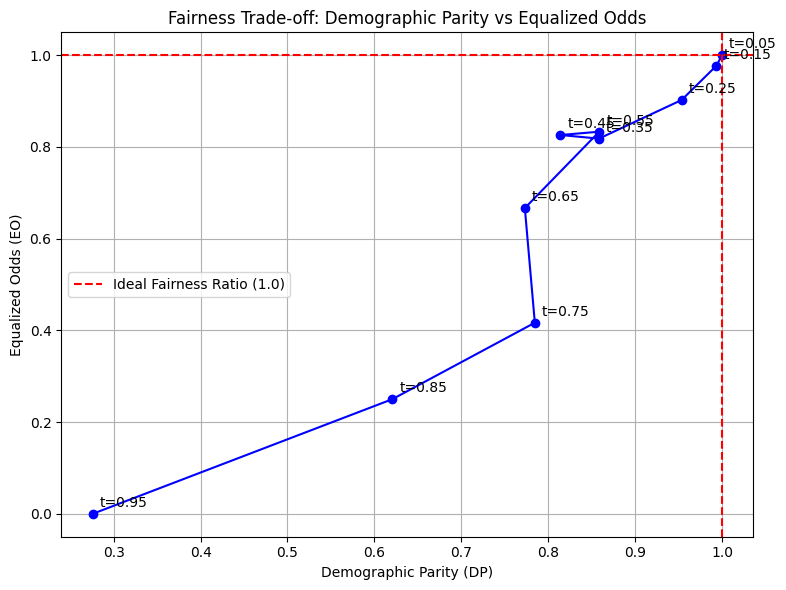

In [ ]:
# Part 2.4: Fairness Trade-Off Analysis Across Thresholds

# Re-assign demographic groups on the test set
test_age_raw = df.loc[X_test.index, 'age']
group_A_mask = (test_age_raw < 30)  # Group A: Younger (<30)
group_B_mask = (test_age_raw >= 30) # Group B: Older (>=30)

y_test_A = y_test[group_A_mask]
y_test_B = y_test[group_B_mask]

probs_A = test_probs[group_A_mask]
probs_B = test_probs[group_B_mask]

thresholds = np.arange(0.05, 1.00, 0.10)
fairness_results = []

for t in thresholds:
    # Classifications at threshold t
    preds_A = (probs_A >= t).astype(int)
    preds_B = (probs_B >= t).astype(int)

    # Selection Rates (P(Y_hat = 1))
    sr_A = np.mean(preds_A) if len(preds_A) > 0 else 0
    sr_B = np.mean(preds_B) if len(preds_B) > 0 else 0
    dp = (sr_A / sr_B) if sr_B > 0 else np.nan

    # True Positive Rate (TPR) and False Positive Rate (FPR)
    tp_A = np.sum((preds_A == 1) & (y_test_A == 1))
    fn_A = np.sum((preds_A == 0) & (y_test_A == 1))
    fp_A = np.sum((preds_A == 1) & (y_test_A == 0))
    tn_A = np.sum((preds_A == 0) & (y_test_A == 0))

    tp_B = np.sum((preds_B == 1) & (y_test_B == 1))
    fn_B = np.sum((preds_B == 0) & (y_test_B == 1))
    fp_B = np.sum((preds_B == 1) & (y_test_B == 0))
    tn_B = np.sum((preds_B == 0) & (y_test_B == 0))

    tpr_A = tp_A / (tp_A + fn_A) if (tp_A + fn_A) > 0 else 0
    tpr_B = tp_B / (tp_B + fn_B) if (tp_B + fn_B) > 0 else 0

    fpr_A = fp_A / (fp_A + tn_A) if (fp_A + tn_A) > 0 else 0
    fpr_B = fp_B / (fp_B + tn_B) if (fp_B + tn_B) > 0 else 0

    tpr_ratio = (tpr_A / tpr_B) if tpr_B > 0 else np.nan
    fpr_ratio = (fpr_A / fpr_B) if fpr_B > 0 else np.nan
    eo = min(tpr_ratio, fpr_ratio) if not np.isnan(tpr_ratio) and not np.isnan(fpr_ratio) else np.nan

    # Predictive Parity (Precision Ratio)
    ppv_A = tp_A / (tp_A + fp_A) if (tp_A + fp_A) > 0 else 0
    ppv_B = tp_B / (tp_B + fp_B) if (tp_B + fp_B) > 0 else 0
    pp = (ppv_A / ppv_B) if ppv_B > 0 else np.nan

    fairness_results.append({
        'Threshold (t)': round(t, 2),
        'Demographic Parity (DP)': round(dp, 4),
        'Equalized Odds (EO)': round(eo, 4),
        'Predictive Parity (PP)': round(pp, 4)
    })

fairness_df = pd.DataFrame(fairness_results)

print("--- PART 2.4 RESULTS ---")
print("Fairness Metrics across Decision Threshold Sweep:")
print(fairness_df.to_string(index=False))

# Plotting Trade-Off Chart: DP vs EO
plt.figure(figsize=(8, 6))
plt.plot(fairness_df['Demographic Parity (DP)'], fairness_df['Equalized Odds (EO)'], marker='o', linestyle='-', color='b')

for i, row in fairness_df.iterrows():
    plt.annotate(f"t={row['Threshold (t)']}",
                 (row['Demographic Parity (DP)'], row['Equalized Odds (EO)']),
                 textcoords="offset points", xytext=(5, 5), ha='left')

plt.axhline(1.0, color='red', linestyle='--', label='Ideal Fairness Ratio (1.0)')
plt.axvline(1.0, color='red', linestyle='--')
plt.title('Fairness Trade-off: Demographic Parity vs Equalized Odds')
plt.xlabel('Demographic Parity (DP)')
plt.ylabel('Equalized Odds (EO)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()